# MVP Geração Z e Álcool | Notebook 01 v1: análise exploratória antes das decisões de tratamento

**Disciplina:** PSP8 (Prof. André Luiz Marques Serrano, EPR/FT/UnB)
**Autor:** Guilherme Augusto Fontes Cunha
**Versão:** v1 (16 out. 2026). Primeira exploração da base. **Nenhuma decisão de tratamento é tomada aqui**: o notebook mostra a base como ela é e termina com a lista de decisões em aberto (seção 14), que serão tomadas pelo autor antes da camada tratada.

**Pergunta do trabalho:** a queda do consumo abusivo de álcool entre jovens é generalizada entre as classes sociais?

## Onde estamos no ciclo de projeto

Etapas 1 (busca) e 2 (coleta e análise exploratória) do ciclo do Módulo 1, com a mesma estrutura do AED v16 do MVP de terras raras: leitura fiel do bruto, conferência, dicionário, faltantes, coerência entre variáveis, pesos, tabela de frequência (Módulo 2) e registro de problemas antes do pré-processamento (Módulo 3).

## Hipótese e perguntas (do README)

> A prevalência de consumo abusivo de álcool entre adultos de 18 a 24 anos nas capitais brasileiras diminuiu entre 2010 e o ano mais recente disponível, e essa queda ocorre em todas as faixas de escolaridade, de forma mais intensa do que entre adultos de faixas etárias mais velhas no mesmo período.

| # | Pergunta | Variáveis da base que a respondem |
|---|---|---|
| P1 | A prevalência entre 18 e 24 anos caiu de 2010 ao ano mais recente? Quantos p.p.? | `ano`, `fet`, `alcabu`, `pesorake2025` |
| P2 | A variação ocorre em todas as faixas de escolaridade? | + `fesc` |
| P3 | A variação dos jovens é maior que a dos adultos de 35 a 44 anos? | `fet` = 1 contra `fet` = 3 |
| P4 | A variação difere entre homens e mulheres? | + `q7` |
| P5 | Quais capitais têm as maiores e menores variações? | + `cidade` |

## Fonte escolhida

**Vigitel Brasil 2006-2024, base harmonizada** (Ministério da Saúde, SVSA/DAENT), publicada em 24/08/2026 em <https://svs.aids.gov.br/daent/cgdnt/vigitel/>. É a base ideal para o MVP porque: (1) é a fonte oficial do indicador de consumo abusivo citado no README; (2) junta todas as edições num único arquivo, com o mesmo dicionário; (3) traz o peso `pesorake2025`, recalibrado pelo Censo 2022 para 2010 a 2024, que a orientação oficial manda usar em análises de série; (4) traz o indicador `alcabu` já calculado. Licença do portal: Creative Commons Atribuição-SemDerivações 3.0.

## Como executar

- **Colab:** *Ambiente de execução > Executar tudo*. O notebook baixa o ZIP (87 MB) do site do Ministério e confere o SHA-256.
- **Databricks:** importe o `.ipynb` e execute. O ZIP é gravado no volume `/Volumes/workspace/genz_alcool/raw/` (coleta persistida na nuvem). Se o cluster não tiver acesso à internet, envie o ZIP para esse volume pela interface (*Catalog > workspace > genz_alcool > raw > Upload*) e execute de novo.
- **Local:** coloque o ZIP em `dados/raw/` do repositório ou na pasta do notebook.

O notebook não importa módulos do repositório: tudo o que ele usa está nele.

## 1. Configuração e reprodutibilidade

In [1]:
import os
import io
import shutil
import zipfile
import hashlib
import platform
import datetime
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

EM_DATABRICKS = 'DATABRICKS_RUNTIME_VERSION' in os.environ
try:
    import google.colab  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False
AMBIENTE = 'Databricks' if EM_DATABRICKS else ('Colab' if EM_COLAB else 'local')

# Cores com função fixa em todos os gráficos (a identidade também vai no rótulo)
COR_JOVEM = '#2a78d6'     # 18 a 24 anos (azul)
COR_REF = '#eb6834'       # 35 a 44 anos, grupo de comparação de P3 (laranja)
COR_OUTROS = '#b8b6ad'    # contexto (cinza)
CORES_ESC = {'0 a 8 anos': '#9ecae1', '9 a 11 anos': '#4292c6', '12 anos e mais': '#08306b'}

print('Ambiente:', AMBIENTE, '| Python', platform.python_version(), '| pandas', pd.__version__,
      '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)
print('Execução:', datetime.datetime.now().strftime('%d/%m/%Y %H:%M'))

Ambiente: local | Python 3.12.10 | pandas 3.0.5 | numpy 2.4.6 | matplotlib 3.11.2
Execução: 16/10/2026 20:33


## 2. Coleta: obtenção do arquivo oficial e conferência de identidade

O arquivo é baixado da página oficial, nunca de espelhos. O SHA-256 abaixo é o do ZIP baixado em 16/10/2026. O Ministério já republicou a base harmonizada (a versão de agosto de 2026 removeu os rótulos das categorias), então **se o hash não bater, os números deste notebook podem não valer** para o arquivo novo.

In [2]:
URL_BASE = 'https://svs.aids.gov.br/daent/cgdnt/vigitel/'
ARQ_ZIP = 'vigitel-2006-2024-peso-rake-csv.zip'
ARQ_DICIONARIO = 'dicionario-vigitel-2006-2024.xlsx'
SHA256_ESPERADO = '40139996d11deb2f52730c90f14e2df4bf5e53aba3cf1848fce391c93ff77993'
TAMANHO_ESPERADO = 87_121_523
EXIGIR_MESMO_ARQUIVO = True   # mude para False só se for analisar conscientemente outra versão

if EM_DATABRICKS:
    CATALOGO, ESQUEMA, VOLUME = 'workspace', 'genz_alcool', 'raw'
    spark.sql(f'CREATE SCHEMA IF NOT EXISTS {CATALOGO}.{ESQUEMA}')
    spark.sql(f'CREATE VOLUME IF NOT EXISTS {CATALOGO}.{ESQUEMA}.{VOLUME}')
    PASTA_DADOS = f'/Volumes/{CATALOGO}/{ESQUEMA}/{VOLUME}'
    PASTA_SAIDAS = f'{PASTA_DADOS}/saidas_aed_v1'
else:
    candidatas = ['.', os.path.join('..', '..', 'dados', 'raw'), os.path.join('dados', 'raw')]
    PASTA_DADOS = next((p for p in candidatas if os.path.exists(os.path.join(p, ARQ_ZIP))), '.')
    PASTA_SAIDAS = 'saidas_aed_v1'


def obter(nome):
    """Devolve o caminho do arquivo; baixa da página oficial se ainda não existir."""
    destino = os.path.join(PASTA_DADOS, nome)
    if os.path.exists(destino):
        return destino
    url = URL_BASE + nome
    print('Baixando', url)
    temporario = os.path.join('/tmp' if os.path.isdir('/tmp') else '.', nome + '.parcial')
    try:
        pedido = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (MVP PSP8 UnB)'})
        with urllib.request.urlopen(pedido, timeout=600) as r, open(temporario, 'wb') as f:
            shutil.copyfileobj(r, f, length=1 << 20)
    except Exception as erro:
        raise RuntimeError(f'Download falhou ({erro}). Baixe {url} manualmente e coloque em {PASTA_DADOS}.')
    shutil.copyfile(temporario, destino)   # cópia (e não move) porque /Volumes não aceita rename entre sistemas
    os.remove(temporario)
    return destino


CAMINHO_ZIP = obter(ARQ_ZIP)
DATA_COLETA = datetime.datetime.fromtimestamp(os.path.getmtime(CAMINHO_ZIP)).strftime('%d/%m/%Y')

h = hashlib.sha256()
with open(CAMINHO_ZIP, 'rb') as f:
    for bloco in iter(lambda: f.read(1 << 20), b''):
        h.update(bloco)
SHA = h.hexdigest()
TAMANHO = os.path.getsize(CAMINHO_ZIP)
print(f'Arquivo: {CAMINHO_ZIP} | {TAMANHO:,} bytes | gravado em {DATA_COLETA}')
print('SHA-256:', SHA)
if SHA != SHA256_ESPERADO:
    msg = 'ATENÇÃO: o ZIP não é a versão usada neste MVP (SHA-256 diferente).'
    if EXIGIR_MESMO_ARQUIVO:
        raise ValueError(msg + ' Confira a data de publicação no site ou mude EXIGIR_MESMO_ARQUIVO.')
    print(msg)
else:
    print('Identidade confirmada: mesma versão do arquivo usada no MVP.')

Arquivo: ..\..\dados\raw\vigitel-2006-2024-peso-rake-csv.zip | 87,121,523 bytes | gravado em 16/10/2026
SHA-256: 40139996d11deb2f52730c90f14e2df4bf5e53aba3cf1848fce391c93ff77993
Identidade confirmada: mesma versão do arquivo usada no MVP.


### 2.1 O que há dentro do ZIP e como o CSV está escrito

Antes de usar `pandas`, o arquivo é lido linha a linha como bytes, para medir três coisas que decidem os parâmetros de leitura: o número de linhas físicas, quantas linhas **não** são UTF-8 válido e quantas têm aspas (campo de texto com vírgula dentro).

In [3]:
with zipfile.ZipFile(CAMINHO_ZIP) as z:
    info = z.infolist()
    for i in info:
        print(f'{i.filename} | {i.file_size:,} bytes descompactado | {i.compress_size:,} compactado')
    NOME_CSV = info[0].filename
    linhas, nao_utf8, com_aspas, exemplos = 0, 0, 0, []
    with z.open(NOME_CSV) as f:
        for bruta in f:
            linhas += 1
            if b'"' in bruta:
                com_aspas += 1
            try:
                bruta.decode('utf-8')
            except UnicodeDecodeError as e:
                nao_utf8 += 1
                if len(exemplos) < 3:
                    exemplos.append(bruta[max(e.start - 40, 0):e.start + 15])

print(f'\nLinhas físicas: {linhas:,} (1 cabeçalho + {linhas - 1:,} registros)')
print(f'Linhas que não são UTF-8 válido: {nao_utf8:,}')
print(f'Linhas com aspas: {com_aspas:,}')
print('Exemplos de trechos não UTF-8:')
for e in exemplos:
    print('   ', e)

vigitel-2006-2024-peso-rake_slabel.csv | 577,433,824 bytes descompactado | 87,121,269 compactado



Linhas físicas: 833,218 (1 cabeçalho + 833,217 registros)
Linhas que não são UTF-8 válido: 1,555
Linhas com aspas: 408
Exemplos de trechos não UTF-8:
    b',,,2,1,1,2,,1,2,,10,1,900,PLANO DA AERON\xc1UTICA,1,0,1,,,'
    b'1,1,,4,4,1,0,1,1,2,1,1,,,,,1,900,ASSOCIA\xc7AO DOS FUNCION'
    b',,2,1,1,,,4,1,1,2,1,2,2,,,,,,1,900,FUNDA\xc7\xc3O COPEU,1,3,1'


**Leitura:** o CSV não tem uma codificação única. A maior parte é ASCII, algumas linhas trazem acentos em latin-1 (por exemplo `AERON\xc1UTICA`) e outras em UTF-8. Todos os casos estão em **campos de texto livre** (nome do plano de saúde, respostas "outros"), que não entram nas perguntas. Por isso a leitura usa `latin-1`, que aceita qualquer byte, e os campos de texto livre ficam fora do recorte. Os campos entre aspas têm vírgulas dentro: um leitor que ignore aspas acharia 487 colunas numa linha de 486.

## 3. Leitura fiel do bruto (recorte de colunas)

O CSV tem 486 colunas e 577 MB. Ler tudo como texto ocuparia vários GB de memória, mais do que o Databricks Free Edition oferece com folga. O recorte abaixo mantém **todas as linhas** e só as colunas ligadas às perguntas, mais as de controle.

| Parâmetro | Valor | Motivo |
|---|---|---|
| `compression` | `zip` | Lê direto do ZIP oficial, sem cópia descompactada |
| `encoding` | `latin-1` | Aceita qualquer byte (seção 2.1) |
| `dtype` | `category`, exceto o peso | Preserva os códigos exatamente como texto (`777`, `888`, vazio) e economiza memória |
| `keep_default_na=False` | vazio continua `''` | Vazio no Vigitel quase sempre é **pulo de questionário**, não perda de dado |

O dataframe `bruto` **nunca é alterado**. A impressão digital calculada abaixo é conferida no fim.

In [4]:
COLUNAS = {
    'chave': 'identificador do entrevistado',
    'ano': 'edição da pesquisa',
    'cidade': 'capital (1 a 27)',
    'regiao': 'região',
    'tipo_fone': 'telefone da entrevista (fixo ou celular)',
    'q6': 'idade em anos',
    'fet': 'faixa etária (6 faixas)',
    'q7': 'sexo',
    'q8a': 'último grau de estudo concluído',
    'q8_anos': 'anos de estudo (algoritmo oficial)',
    'fesc': 'faixa de escolaridade (3 faixas, usada na ponderação)',
    'q35': 'costuma consumir bebida alcoólica?',
    'q36': 'frequência de consumo',
    'q37': '5+ doses numa ocasião nos últimos 30 dias (homem)',
    'q38': '4+ doses numa ocasião nos últimos 30 dias (mulher)',
    'q37a': 'versão 2006 da pergunta (homem)',
    'q38a': 'versão 2006 da pergunta (mulher)',
    'q37b': 'versão 2006-2008 da pergunta (homem)',
    'q38b': 'versão 2006-2008 da pergunta (mulher)',
    'alcabu': 'indicador oficial: consumo abusivo (episódico pesado)',
    'pesorake2025': 'peso amostral (rake, Censo 2022)',
}

with zipfile.ZipFile(CAMINHO_ZIP) as z, z.open(NOME_CSV) as f:
    TODAS_COLUNAS = list(pd.read_csv(f, encoding='latin-1', nrows=0).columns)
print('Colunas no arquivo:', len(TODAS_COLUNAS))
print('Colunas do recorte ausentes no arquivo:', [c for c in COLUNAS if c not in TODAS_COLUNAS])

tipos = {c: 'category' for c in COLUNAS}
tipos['pesorake2025'] = str
bruto = pd.read_csv(CAMINHO_ZIP, compression='zip', encoding='latin-1', usecols=list(COLUNAS),
                    dtype=tipos, keep_default_na=False)[list(COLUNAS)]
assert len(bruto) == linhas - 1, 'O pandas leu um número de registros diferente das linhas físicas'

DIGITAL_BRUTO = pd.util.hash_pandas_object(bruto, index=True).sum()
print(f'Registros: {len(bruto):,} | Colunas no recorte: {bruto.shape[1]} | '
      f'Memória: {bruto.memory_usage(deep=True).sum() / 1e6:,.0f} MB')

Colunas no arquivo: 486
Colunas do recorte ausentes no arquivo: []


Registros: 833,217 | Colunas no recorte: 21 | Memória: 97 MB


## 4. Conferência da leitura

In [5]:
display(bruto.head(3))
display(bruto.tail(3))

,chave,ano,cidade,regiao,tipo_fone,q6,fet,q7,q8a,q8_anos,fesc,q35,q36,q37,q38,q37a,q38a,q37b,q38b,alcabu,pesorake2025
0,,2006,7,5,,37,3,2,3,8,1,1,4,,,,1,,1,1,586.9559936523438
1,,2006,27,1,,40,3,2,4,11,2,3,,,,,,,,0,615.216552734375
2,,2006,10,1,,64,5,2,3,5,1,1,4,,,,1,,1,1,593.0910034179688


,chave,ano,cidade,regiao,tipo_fone,q6,fet,q7,q8a,q8_anos,fesc,q35,q36,q37,q38,q37a,q38a,q37b,q38b,alcabu,pesorake2025
833214,,2024,8,5,FIXO,71,6,2,6,15,3,,5,,2,,,,,0,508315.125
833215,,2024,3,4,FIXO,76,6,2,6,15,3,,6,,,,,,,0,2270807.5
833216,,2024,3,4,CELULAR,71,6,2,6,15,3,,6,,,,,,,0,1678060


In [6]:
resumo = pd.DataFrame({
    'descrição': pd.Series(COLUNAS),
    'distintos': bruto.nunique(),
    'vazios': (bruto == '').sum(),
    '% vazio': ((bruto == '').mean() * 100).round(1),
    'exemplos': bruto.apply(lambda c: ', '.join(map(str, sorted(c.astype(str).unique())[:6]))),
})
print('Linhas 100% duplicadas no recorte:', bruto.duplicated().sum())
resumo

Linhas 100% duplicadas no recorte: 58119


,descrição,distintos,vazios,% vazio,exemplos
chave,identificador do entrevistado,295969,451248,54.2,", 00210121030, 00210141029, 00210211030, 00210..."
ano,edição da pesquisa,18,0,0.0,"2006, 2007, 2008, 2009, 2010, 2011"
cidade,capital (1 a 27),27,0,0.0,"1, 10, 11, 12, 13, 14"
regiao,região,6,45448,5.5,", 1, 2, 3, 4, 5"
tipo_fone,telefone da entrevista (fixo ou celular),3,784479,94.2,", CELULAR, FIXO"
q6,idade em anos,94,0,0.0,"100, 101, 102, 103, 104, 105"
fet,faixa etária (6 faixas),6,0,0.0,"1, 2, 3, 4, 5, 6"
q7,sexo,2,0,0.0,"1, 2"
q8a,último grau de estudo concluído,13,346,0.0,", 1, 10, 2, 3, 4"
q8_anos,anos de estudo (algoritmo oficial),1170,0,0.0,"0, 1, 10, 10.023255, 10.027933, 10.028571"


**Leitura:** a base está em **formato largo**: cada linha é **um entrevistado** de uma edição e cada coluna é uma pergunta ou uma variável derivada. Os vazios não são, em geral, dados perdidos: as perguntas de doses (`q37`, `q38`) só são feitas a quem bebe, e cada uma a um sexo. As 58 mil linhas 100% duplicadas no recorte são, em princípio, pessoas diferentes com as mesmas respostas nas 21 colunas: sem uma chave confiável (seção 6) não há como distingui-las, e por isso elas não são removidas.

### 4.1 Mapa de vazios por edição

Como as perguntas mudaram ao longo de 18 edições, o vazio precisa ser lido **por ano**. O mapa mostra a porcentagem de vazios de cada coluna em cada edição.

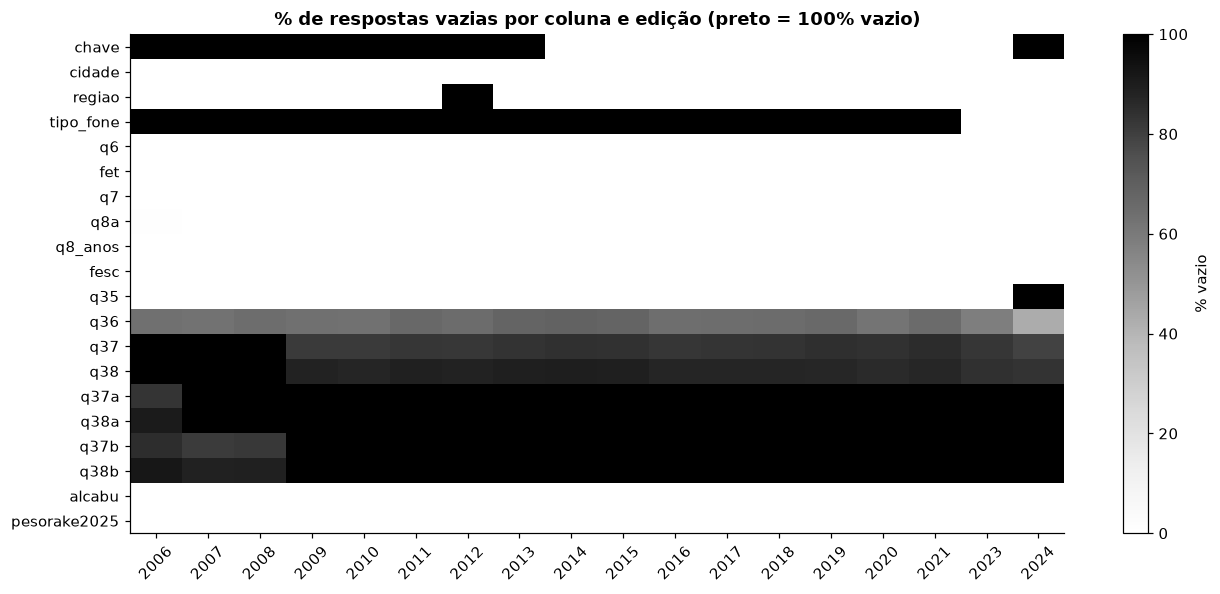

ano,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2023,2024
chave,100,100,100,100,100,100,100,100,0,0,0,0,0,0,0,0,0,100
cidade,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
regiao,0,0,0,0,0,0,100,0,0,0,0,0,0,0,0,0,0,0
tipo_fone,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,0,0
q6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
fet,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
q7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
q8a,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
q8_anos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
fesc,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [7]:
mapa_vazios = (bruto.drop(columns=['ano']) == '').groupby(bruto['ano'], observed=True).mean() * 100
fig, ax = plt.subplots(figsize=(12, 5.5))
im = ax.imshow(mapa_vazios.T.values, aspect='auto', cmap='Greys', vmin=0, vmax=100)
ax.set_xticks(range(len(mapa_vazios.index)), mapa_vazios.index, rotation=45)
ax.set_yticks(range(len(mapa_vazios.columns)), mapa_vazios.columns)
ax.set_title('% de respostas vazias por coluna e edição (preto = 100% vazio)')
fig.colorbar(im, ax=ax, label='% vazio')
plt.tight_layout()
plt.show()
mapa_vazios.round(0).astype(int).T

**Leitura:** o mapa expõe três rupturas no questionário de álcool. (1) As perguntas de doses têm **nomes diferentes por período**: `q37a`/`q38a` só em 2006, `q37b`/`q38b` em 2006 a 2008 e `q37`/`q38` de 2009 em diante. (2) `q35` está **100% vazia em 2024**. (3) `chave` está vazia em 2006-2013 e em 2024, e `regiao` está vazia em toda a edição de 2012 (a análise usa `cidade`, que é completa). Também chamam a atenção `q8_anos`, `fesc`, `fet`, `alcabu` e o peso, **sem nenhum vazio** em nenhum ano: são variáveis derivadas e imputadas pelo Ministério.

## 5. Dicionário do recorte

Os códigos abaixo foram transcritos do dicionário oficial (`dicionario-vigitel-2006-2024.xlsx`, aba *Variáveis_Vigitel*). A base de agosto de 2026 foi publicada **sem rótulos**, de propósito, para evitar divergência com o dicionário, então os rótulos vêm daqui.

| Coluna | Classificação (Módulo 2) | Códigos |
|---|---|---|
| `ano` | Quantitativa discreta (usada como categoria de tempo) | 2006 a 2024, sem 2022 |
| `cidade` | Qualitativa nominal | 1 a 27 (26 capitais e Distrito Federal) |
| `q6` | Quantitativa discreta | idade em anos |
| `fet` | Qualitativa ordinal | 1 = 18-24, 2 = 25-34, 3 = 35-44, 4 = 45-54, 5 = 55-64, 6 = 65+ |
| `q7` | Qualitativa nominal | 1 = masculino, 2 = feminino |
| `q8a` | Qualitativa ordinal | 1 primário ... 6 superior, 7 pós, 8 nunca estudou, 777 não sabe, 888 não quis responder |
| `q8_anos` | Quantitativa contínua | 0 a 20 (pode ter decimais imputados) |
| `fesc` | Qualitativa ordinal | 1 = 0 a 8 anos, 2 = 9 a 11 anos, 3 = 12 anos e mais |
| `q35` | Qualitativa nominal | 1 = sim; 2 = não (até 2019) ou "sim, mas não no último mês" (2020+); 3 = não consumo; 4 = nunca consumi; 888 = não quis informar |
| `q37`, `q38` | Qualitativa nominal (binária) | 1 = sim, 2 = não |
| `alcabu` | Qualitativa nominal (binária) | 0 = não, 1 = sim |
| `pesorake2025` | Quantitativa contínua | peso de pós-estratificação (rake) |

Rotina oficial do indicador, na aba *Indicadores_Vigitel*: `gen alcabu = cond(q37==1 | q38==1, 1, 0)`. Como o indicador vale 0 para quem não bebe, **o denominador é toda a população adulta**, e não só quem bebe.

In [8]:
ROTULOS = {
    'fet': {'1': '18 a 24', '2': '25 a 34', '3': '35 a 44', '4': '45 a 54', '5': '55 a 64', '6': '65 e mais'},
    'q7': {'1': 'masculino', '2': 'feminino'},
    'fesc': {'1': '0 a 8 anos', '2': '9 a 11 anos', '3': '12 anos e mais'},
    'cidade': {str(i): n for i, n in enumerate(
        ['Aracaju', 'Belém', 'Belo Horizonte', 'Boa Vista', 'Campo Grande', 'Cuiabá', 'Curitiba',
         'Florianópolis', 'Fortaleza', 'Goiânia', 'João Pessoa', 'Macapá', 'Maceió', 'Manaus', 'Natal',
         'Palmas', 'Porto Alegre', 'Porto Velho', 'Recife', 'Rio Branco', 'Rio de Janeiro', 'Salvador',
         'São Luís', 'São Paulo', 'Teresina', 'Vitória', 'Distrito Federal'], start=1)},
}

# Tentativa de ler a rotina oficial no próprio dicionário (precisa de openpyxl; se falhar, o texto acima vale)
try:
    dic = pd.read_excel(obter(ARQ_DICIONARIO), sheet_name='Indicadores_Vigitel', header=3)
    display(dic[dic.iloc[:, 0].astype(str).str.strip().eq('alcabu')].iloc[:, [0, 4, 7]])
except Exception as erro:
    print('Dicionário não lido neste ambiente:', erro)

,fumante,Fumantes,"gen fumante = cond(q60<3 & q60!=., 1, 0)"
116,alcabu,Consumo abusivo de alcool,"gen alcabu = cond(q37==1 | q38==1, 1, 0)"


## 6. Unidade de observação e chave

Para juntar tabelas no pipeline (modelo estrela), cada entrevistado precisa de um identificador único. A base traz a coluna `chave`.

In [9]:
ch = bruto['chave'].astype(str)
preenchida = ch != ''
print(f'chave vazia: {(~preenchida).sum():,} registros ({(~preenchida).mean():.1%})')
print(f'chave preenchida: {preenchida.sum():,} | valores distintos entre as preenchidas: {ch[preenchida].nunique():,}')
print(f'registros com chave repetida (preenchida): {ch[preenchida].duplicated(keep=False).sum():,}')
pd.crosstab(bruto['ano'], np.where(preenchida, 'preenchida', 'vazia'))

chave vazia: 451,248 registros (54.2%)
chave preenchida: 381,969 | valores distintos entre as preenchidas: 295,968


registros com chave repetida (preenchida): 147,263


col_0,preenchida,vazia
ano,,
2006,0,54369
2007,0,54251
2008,0,54353
2009,0,54367
2010,0,54339
2011,0,54144
2012,0,45448
2013,0,52929
2014,40853,0


## 7. Cobertura temporal e tamanho da amostra

A pergunta compara 2010 com o ano mais recente. O tamanho da amostra de cada recorte (jovens, jovens por escolaridade, jovens por capital) define o que dá para responder com precisão.

In [10]:
explo = pd.DataFrame({
    'ano': bruto['ano'].astype(int),
    'cidade': bruto['cidade'].astype(str).map(ROTULOS['cidade']),
    'idade': pd.to_numeric(bruto['q6'].astype(str)),
    'fet': bruto['fet'].astype(str),
    'sexo': bruto['q7'].astype(str).map(ROTULOS['q7']),
    'fesc': bruto['fesc'].astype(str).map(ROTULOS['fesc']),
    'anos_estudo': pd.to_numeric(bruto['q8_anos'].astype(str), errors='coerce'),
    'alcabu': pd.to_numeric(bruto['alcabu'].astype(str)),
    'peso': pd.to_numeric(bruto['pesorake2025']),
    'fone': bruto['tipo_fone'].astype(str).replace('', '(vazio)'),
})
jovem = explo['fet'] == '1'
ANOS = sorted(explo['ano'].unique())
print('Edições:', ANOS)
print('Edições ausentes entre 2006 e 2024:', sorted(set(range(2006, 2025)) - set(ANOS)))

amostra = pd.DataFrame({
    'entrevistas': explo.groupby('ano').size(),
    '18 a 24': explo[jovem].groupby('ano').size(),
    '35 a 44': explo[explo['fet'] == '3'].groupby('ano').size(),
})
amostra['% jovens na amostra'] = (amostra['18 a 24'] / amostra['entrevistas'] * 100).round(1)
amostra

Edições: [np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2023), np.int64(2024)]
Edições ausentes entre 2006 e 2024: [2022]


,entrevistas,18 a 24,35 a 44,% jovens na amostra
ano,,,,
2006,54369,8770,12158,16.1
2007,54251,8432,12058,15.5
2008,54353,8036,11677,14.8
2009,54367,7760,11369,14.3
2010,54339,7364,10902,13.6
2011,54144,6971,10436,12.9
2012,45448,5353,8580,11.8
2013,52929,5834,9069,11.0
2014,40853,4316,7054,10.6


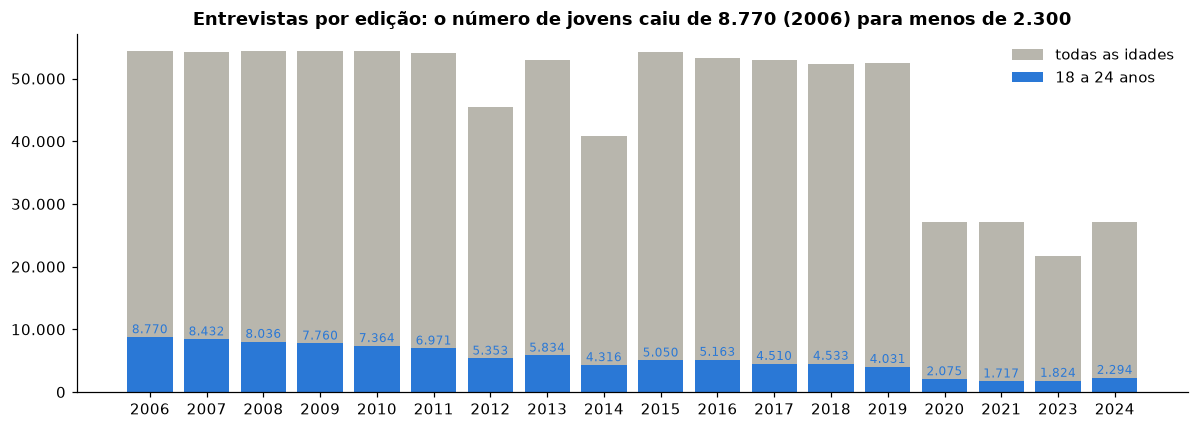

In [11]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(amostra))
ax.bar(x, amostra['entrevistas'], color=COR_OUTROS, label='todas as idades')
ax.bar(x, amostra['18 a 24'], color=COR_JOVEM, label='18 a 24 anos')
for xi, v in zip(x, amostra['18 a 24']):
    ax.text(xi, v + 600, f'{v:,}'.replace(',', '.'), ha='center', fontsize=8, color=COR_JOVEM)
ax.set_xticks(x, amostra.index)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
ax.set_title('Entrevistas por edição: o número de jovens caiu de 8.770 (2006) para menos de 2.300')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 7.1 Células das perguntas P2 e P5

Quantos jovens há em cada faixa de escolaridade (P2) e em cada capital (P5), nos anos das comparações.

In [12]:
celulas_p2 = pd.crosstab(explo.loc[jovem, 'ano'], explo.loc[jovem, 'fesc'])[list(CORES_ESC)]
display(celulas_p2)

celulas_p5 = pd.crosstab(explo.loc[jovem, 'cidade'], explo.loc[jovem, 'ano'])
print('Jovens por capital: resumo por edição (mínimo, mediana, máximo)')
display(celulas_p5.agg(['min', 'median', 'max']).T.astype(int).T)
print('Capitais com menos de 100 jovens entrevistados em 2024:', (celulas_p5[2024] < 100).sum(), 'de 27')
print('Menores amostras de 2024:', celulas_p5[2024].nsmallest(5).to_dict())

fesc,0 a 8 anos,9 a 11 anos,12 anos e mais
ano,,,
2006,1042,4867,2861
2007,864,4865,2703
2008,767,4441,2828
2009,628,4236,2896
2010,610,3847,2907
2011,592,3770,2609
2012,446,2778,2129
2013,385,3000,2449
2014,286,2271,1759


Jovens por capital: resumo por edição (mínimo, mediana, máximo)


ano,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2023,2024
min,221,213,200,189,179,170,114,141,91,105,99,90,90,94,33,32,47,53
median,325,306,305,287,270,255,195,214,154,180,190,165,164,142,73,60,68,84
max,433,410,400,381,391,338,278,305,235,281,318,298,251,209,133,112,102,133


Capitais com menos de 100 jovens entrevistados em 2024: 20 de 27
Menores amostras de 2024: {'Florianópolis': 53, 'Porto Alegre': 57, 'Fortaleza': 60, 'São Paulo': 62, 'Curitiba': 65}


## 8. Modo de coleta: telefone fixo e celular

In [13]:
pd.crosstab(explo['ano'], explo['fone'], margins=True)

fone,(vazio),CELULAR,FIXO,All
ano,,,,
2006,54369,0,0,54369
2007,54251,0,0,54251
2008,54353,0,0,54353
2009,54367,0,0,54367
2010,54339,0,0,54339
2011,54144,0,0,54144
2012,45448,0,0,45448
2013,52929,0,0,52929
2014,40853,0,0,40853


**Leitura:** até 2021 o Vigitel entrevistou **só por telefone fixo**; a coluna vem vazia porque não havia o que distinguir. Em 2023 metade das entrevistas foi por celular e em 2024 mais de 90%. Jovens são justamente o grupo menos alcançável por linha fixa. Comparar 2010 com 2024 é, portanto, comparar **dois modos de coleta diferentes**, e a mudança pode alterar quem responde. O peso rake corrige a composição por sexo, idade e escolaridade, mas não diferenças de comportamento entre quem tem e quem não tem telefone fixo.

## 9. Idade e faixa etária

In [14]:
faixa_recalc = pd.cut(explo['idade'], [17, 24, 34, 44, 54, 64, 200], labels=list('123456')).astype(str)
print('Registros em que fet não bate com a idade:', (faixa_recalc != explo['fet']).sum())
print('Idade mínima:', explo['idade'].min(), '| máxima:', explo['idade'].max())
print('Registros com idade acima de 100 anos:', (explo['idade'] > 100).sum())
print('\nIdades dos jovens: distribuição em 2010 e 2024 (% dentro do ano)')
pd.crosstab(explo.loc[jovem, 'idade'], explo.loc[jovem, 'ano'], normalize='columns')[[2010, 2024]].mul(100).round(1).T

Registros em que fet não bate com a idade: 0
Idade mínima: 18 | máxima: 120
Registros com idade acima de 100 anos: 46

Idades dos jovens: distribuição em 2010 e 2024 (% dentro do ano)


idade,18,19,20,21,22,23,24
ano,,,,,,,
2010,14.8,13.2,14.6,14.0,15.6,14.0,13.8
2024,12.5,11.9,14.1,13.1,15.9,15.7,16.8


**Leitura:** `fet` é coerente com a idade em todos os registros, então não há o que recalcular. Idades acima de 100 anos não afetam as perguntas, que só usam 18-24 e 35-44.

## 10. Escolaridade: a proxy de classe social

### 10.1 Coerência entre `q8a`, `q8_anos` e `fesc`

In [15]:
fesc_recalc = pd.cut(explo['anos_estudo'], [-1, 8.999, 11.999, 99], labels=list(CORES_ESC)).astype(str)
print('fesc diferente da faixa recalculada pelos anos de estudo:', (fesc_recalc != explo['fesc']).sum())
print('q8a com 777 (não sabe) ou 888 (não quis responder):',
      bruto['q8a'].isin(['777', '888']).sum(), '| q8a vazia:', (bruto['q8a'] == '').sum())
print('...e mesmo assim fesc vazia:', (bruto['fesc'] == '').sum(), '(o Ministério imputa a escolaridade)')
print('\nCódigos de q8a por edição (2006 usa outra codificação):')
pd.crosstab(bruto['ano'], bruto['q8a'])

fesc diferente da faixa recalculada pelos anos de estudo: 0
q8a com 777 (não sabe) ou 888 (não quis responder): 8170 | q8a vazia: 346
...e mesmo assim fesc vazia: 0 (o Ministério imputa a escolaridade)

Códigos de q8a por edição (2006 usa outra codificação):


q8a,,1,2,3,4,5,6,7,8,9,10,777,888
ano,,,,,,,,,,,,,
2006,346,5477,2290,7906,20268,69,204,13919,2351,1489,50,0,0
2007,0,4177,111,735,9648,21121,14036,2762,1430,0,0,152,79
2008,0,3550,95,744,10051,21164,14662,2560,1321,0,0,109,97
2009,0,3007,91,1097,9466,21133,15358,2743,1216,0,0,124,132
2010,0,2926,99,772,9987,20795,15574,2812,1075,0,0,134,165
2011,0,3674,128,887,9718,20587,14670,2875,1175,0,0,178,252
2012,0,2366,64,909,8299,17552,12479,2472,918,0,0,200,189
2013,0,3352,135,1232,8655,19293,14953,3412,1146,0,0,246,505
2014,0,2652,116,865,7173,15286,10357,2952,931,0,0,181,340


**Leitura:** `fesc` não tem vazios, mesmo havendo milhares de `q8a` = 777 ou 888: a faixa de escolaridade é **imputada** pelo Ministério, porque entra no cálculo do peso. Em 2006 `q8a` usa outra codificação (aparecem os códigos 9 e 10 e a distribuição é diferente). Isso não afeta a análise se ela usar `fesc` e começar em 2010. `fesc` bate com a faixa recalculada a partir de `q8_anos` em 100% dos registros.

### 10.2 Tabela de frequência da escolaridade dos jovens (Módulo 2: fi, fr, Fac, Frac)

A tabela é feita **sem peso** (descreve a amostra) e **com peso** (estima a população). A diferença entre as duas mostra o quanto a amostra se afasta da população e por que o peso é obrigatório.

In [16]:
def tabela_frequencia(serie, pesos=None, ordem=None):
    contagem = (serie.value_counts() if pesos is None else pesos.groupby(serie, observed=True).sum())
    contagem = contagem.reindex(ordem) if ordem else contagem
    t = pd.DataFrame({'fi': contagem})
    t['fr (%)'] = t['fi'] / t['fi'].sum() * 100
    t['Fac'] = t['fi'].cumsum()
    t['Frac (%)'] = t['fr (%)'].cumsum()
    return t


for ano in (2010, 2024):
    sel = jovem & (explo['ano'] == ano)
    sem = tabela_frequencia(explo.loc[sel, 'fesc'], ordem=list(CORES_ESC))
    com = tabela_frequencia(explo.loc[sel, 'fesc'], explo.loc[sel, 'peso'], ordem=list(CORES_ESC))
    print(f'Jovens de 18 a 24 anos, {ano}')
    display(pd.concat({'amostra (sem peso)': sem.round(1), 'população (com peso)': com[['fr (%)', 'Frac (%)']].round(1)}, axis=1))

Jovens de 18 a 24 anos, 2010


amostra (sem peso)                       população (com peso)         
                               fi fr (%)   Fac Frac (%)               fr (%) Frac (%)
fesc                                                                                 
0 a 8 anos                    610    8.3   610      8.3                 14.4     14.4
9 a 11 anos                  3847   52.2  4457     60.5                 54.4     68.8
12 anos e mais               2907   39.5  7364    100.0                 31.2    100.0

Jovens de 18 a 24 anos, 2024


amostra (sem peso)                       população (com peso)         
                               fi fr (%)   Fac Frac (%)               fr (%) Frac (%)
fesc                                                                                 
0 a 8 anos                    131    5.7   131      5.7                  8.3      8.3
9 a 11 anos                  1407   61.3  1538     67.0                 58.7     67.0
12 anos e mais                756   33.0  2294    100.0                 33.0    100.0

**Leitura:** a composição dos jovens por escolaridade **mudou entre 2010 e 2024**: na população (com peso), a faixa de 0 a 8 anos caiu de 14,4% para 8,3% e a de 9 a 11 anos subiu de 54,4% para 58,7%. A amostra sem peso tem jovens de alta escolaridade a mais (39,5% contra 31,2% em 2010), o que confirma que proporção sem peso não representa a população. Isso é central para P2: se a prevalência geral dos jovens muda, parte da mudança pode vir só de haver mais jovens numa faixa do que na outra (efeito composição), e não de mudança de comportamento dentro de cada faixa. Por isso a P2 deve ser respondida **dentro de cada faixa**, e não pela média geral.

## 11. A medida de consumo

### 11.1 A pergunta de entrada (`q35`) mudou de codificação

In [17]:
pd.crosstab(bruto['ano'], bruto['q35'])

q35,1,2,3,4,888,
ano,,,,,,
2006,19963,1128,28869,4409,0,0
2007,20324,33927,0,0,0,0
2008,19287,35066,0,0,0,0
2009,19837,34530,0,0,0,0
2010,20058,34281,0,0,0,0
2011,18176,35968,0,0,0,0
2012,15954,29494,0,0,0,0
2013,17154,35775,0,0,0,0
2014,12786,28062,0,0,5,0


**Leitura:** a codificação de `q35` mudou duas vezes (2006 tinha 4 opções; de 2007 a 2019, 2 opções; de 2020 em diante, 3 opções com "sim, mas não no último mês") e **a pergunta não está na base de 2024**. Qualquer indicador de "bebe" ou "não bebe" construído com `q35` não seria comparável entre 2010 e 2024. O `alcabu` não depende de `q35`.

### 11.2 Quem responde `q37` e `q38`

In [18]:
quem = pd.DataFrame({
    'q37 preenchida': bruto['q37'] != '',
    'q38 preenchida': bruto['q38'] != '',
    'sexo': explo['sexo'],
    'ano': explo['ano'],
})
quem = quem[quem['ano'] >= 2009]
pd.crosstab([quem['sexo']], [quem['q37 preenchida'], quem['q38 preenchida']])

q37 preenchida   False          True 
q38 preenchida   False  True    False
sexo                                 
feminino        334470  82480       0
masculino       139022      0  114272

**Leitura (2009 em diante):** `q37` só é perguntada a homens e `q38` só a mulheres, nunca as duas à mesma pessoa. O vazio é **pulo de questionário** (mulher não responde `q37`; quem não bebe não responde nenhuma), e não dado faltante.

### 11.3 O nome das variáveis contradiz o documento de orientações

In [19]:
uso = pd.DataFrame({c: (bruto[c] != '').groupby(bruto['ano'], observed=True).sum()
                    for c in ['q37a', 'q38a', 'q37b', 'q38b', 'q37', 'q38']})
uso

,q37a,q38a,q37b,q38b,q37,q38
ano,,,,,,
2006,9177,5101,8234,4406,0,0
2007,0,0,10211,6147,0,0
2008,0,0,9777,6087,0,0
2009,0,0,0,0,10157,6545
2010,0,0,0,0,10023,6946
2011,0,0,0,0,9450,5956
2012,0,0,0,0,8029,5332
2013,0,0,0,0,8717,5728
2014,0,0,0,0,6495,4198


**Leitura:** o documento *Orientações para análise do Vigitel 2006-2024* (item 3.3) diz que, **a partir de 2010**, as perguntas passaram a se chamar `q37b` e `q38b`. A base mostra o **oposto**: `q37b`/`q38b` aparecem só em 2006-2008 e `q37`/`q38` de 2009 em diante. A rotina oficial do `alcabu`, no dicionário, usa `q37`/`q38`. A divergência fica registrada e precisa ser checada nos questionários dos relatórios de 2009 e 2010, que trazem a redação de cada pergunta.

### 11.4 O `alcabu` oficial pode ser reproduzido?

In [20]:
sim = lambda c: bruto[c].astype(str) == '1'
reconstruido = (sim('q37') | sim('q38') | sim('q37b') | sim('q38b')).astype(int)
confere = reconstruido == explo['alcabu']
print(f'alcabu oficial = (q37 ou q38 ou q37b ou q38b igual a 1) em {confere.mean():.4%} dos registros')
print('Divergências:', (~confere).sum())
so_oficial = ((sim('q37') | sim('q38')).astype(int) == explo['alcabu'])
print('Usando só q37 e q38 (rotina do dicionário), divergências por edição:')
print((~so_oficial).groupby(explo['ano']).sum().to_dict())

alcabu oficial = (q37 ou q38 ou q37b ou q38b igual a 1) em 100.0000% dos registros
Divergências: 0
Usando só q37 e q38 (rotina do dicionário), divergências por edição:
{2006: 8094, 2007: 8828, 2008: 8781, 2009: 0, 2010: 0, 2011: 0, 2012: 0, 2013: 0, 2014: 0, 2015: 0, 2016: 0, 2017: 0, 2018: 0, 2019: 0, 2020: 0, 2021: 0, 2023: 0, 2024: 0}


**Leitura:** o `alcabu` publicado é reproduzido em 100% dos registros quando se juntam os dois pares de nomes. A rotina literal do dicionário (só `q37`/`q38`) reproduz o indicador **de 2009 em diante**, o período das perguntas, mas daria zero para todos em 2006-2008. Como a análise começa em 2010, as duas formas dão o mesmo resultado no período de interesse.

## 12. Pesos amostrais (`pesorake2025`)

In [21]:
pesos = explo.groupby('ano')['peso'].agg(['count', 'min', 'median', 'max', 'sum'])
pesos['max / min'] = pesos['max'] / pesos['min']
pesos['n efetivo (Kish)'] = explo.groupby('ano')['peso'].apply(lambda w: w.sum() ** 2 / (w ** 2).sum())
pesos['n efetivo / n'] = pesos['n efetivo (Kish)'] / pesos['count']
pesos.style.format({'min': '{:,.1f}', 'median': '{:,.1f}', 'max': '{:,.0f}', 'sum': '{:,.3e}',
                    'max / min': '{:,.0f}', 'n efetivo (Kish)': '{:,.0f}', 'n efetivo / n': '{:.2f}'})

,count,min,median,max,sum,max / min,n efetivo (Kish),n efetivo / n
ano,,,,,,,,
2006,54369,3.1,244.0,"20,668",3.005e+07,"6,676","12,979",0.24
2007,54251,1.9,257.2,"23,633",3.178e+07,"12,186","12,986",0.24
2008,54353,1.7,256.5,"21,517",3.199e+07,"12,496","13,039",0.24
2009,54367,2.4,253.6,"30,710",3.249e+07,"12,655","12,217",0.22
2010,54339,"30,826.6","537,470.9","33,644,360",6.612e+10,"1,091","12,910",0.24
2011,54144,"31,654.1","566,350.3","33,797,688",6.690e+10,"1,068","13,691",0.25
2012,45448,"32,523.0","556,376.4","33,962,216",5.699e+10,"1,044","11,067",0.24
2013,52929,"33,435.5","531,876.3","34,138,180",6.627e+10,"1,021","12,787",0.24
2014,40853,"34,394.2","532,749.2","34,325,824",5.138e+10,998,"9,843",0.24


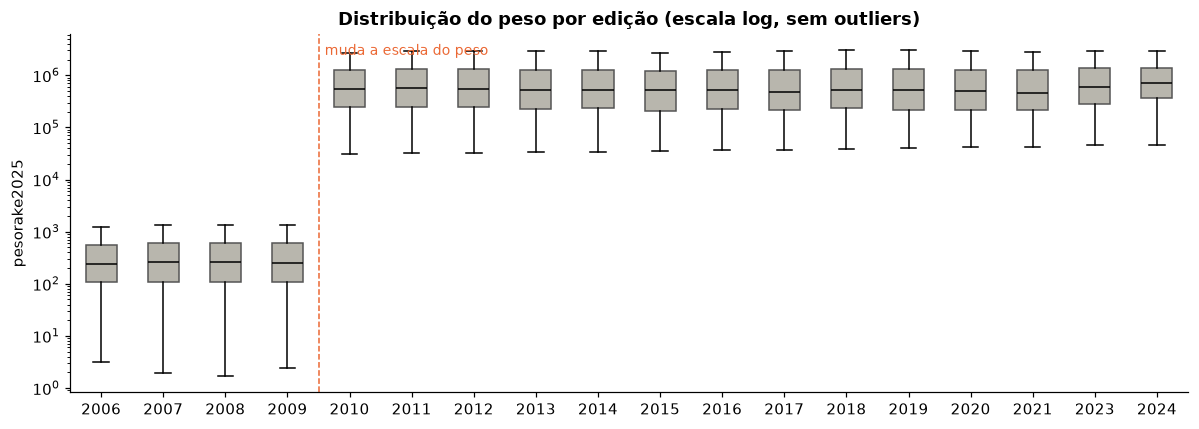

In [22]:
fig, ax = plt.subplots(figsize=(11, 4))
dados_box = [explo.loc[explo['ano'] == a, 'peso'] for a in ANOS]
ax.boxplot(dados_box, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor=COR_OUTROS, edgecolor='#555'), medianprops=dict(color='black'))
ax.set_xticks(range(1, len(ANOS) + 1), [str(a) for a in ANOS])
ax.set_yscale('log')
ax.axvline(4.5, color=COR_REF, ls='--', lw=1)
ax.text(4.6, ax.get_ylim()[1] * 0.4, 'muda a escala do peso', color=COR_REF, fontsize=9)
ax.set_title('Distribuição do peso por edição (escala log, sem outliers)')
ax.set_ylabel('pesorake2025')
plt.tight_layout()
plt.show()

**Leitura:** o peso **muda de escala entre 2009 e 2010**: até 2009 a soma dos pesos é da ordem de 30 milhões (a população adulta das capitais); de 2010 em diante, da ordem de 60 bilhões. É coerente com a orientação oficial: `pesorake2025` junta os pesos antigos (2006-2009) com os recalibrados pelo Censo 2022 (2010-2024). **Dentro de cada ano** isso não afeta prevalências, que são razões. Mas qualquer conta que some pesos de anos diferentes (por exemplo, juntar 2009 e 2010 numa média) ficaria dominada pelos anos de escala maior. A coluna *n efetivo* (fórmula de Kish) mostra quanto a variação dos pesos reduz a precisão: os intervalos da seção 13 usam esse *n* menor.

## 13. Prévia descritiva das perguntas (não é o teste das hipóteses)

As prevalências abaixo são **ponderadas** por `pesorake2025` e têm um intervalo de 95% **aproximado**, calculado com o *n* efetivo de Kish. O intervalo exato exige o desenho amostral completo, o que fica para a camada analítica. O objetivo aqui é só ver a forma dos dados antes de decidir o tratamento.

As linhas verticais marcam as duas rupturas registradas: a falta da edição de 2022 e a entrada do celular em 2023.

In [23]:
def prevalencia(df, por):
    g = df.assign(wy=df['peso'] * df['alcabu'], w2=df['peso'] ** 2)
    r = g.groupby(por, observed=True).agg(n=('alcabu', 'size'), soma_w=('peso', 'sum'),
                                          soma_wy=('wy', 'sum'), soma_w2=('w2', 'sum')).reset_index()
    r['prev'] = r['soma_wy'] / r['soma_w'] * 100
    r['n_efetivo'] = r['soma_w'] ** 2 / r['soma_w2']
    ep = np.sqrt(r['prev'] / 100 * (1 - r['prev'] / 100) / r['n_efetivo']) * 100
    r['ic95_inf'], r['ic95_sup'] = r['prev'] - 1.96 * ep, r['prev'] + 1.96 * ep
    return r.drop(columns=['soma_w', 'soma_wy', 'soma_w2'])


def marcar_rupturas(ax):
    ax.set_xticks(range(2006, 2025, 2))
    ax.set_xlim(2005.5, 2024.5)
    ax.axvspan(2021.5, 2022.5, color='#eeeeee', zorder=0)
    ax.axvline(2022.5, color='#777', ls=':', lw=1)
    ax.text(2022, ax.get_ylim()[1], 'sem\n2022', ha='center', va='top', fontsize=8, color='#555')
    ax.text(2022.6, ax.get_ylim()[0], ' celular', va='bottom', fontsize=8, color='#555')


def linha(ax, r, cor, rotulo):
    ax.plot(r['ano'], r['prev'], marker='o', color=cor, label=rotulo, lw=2)
    ax.fill_between(r['ano'], r['ic95_inf'], r['ic95_sup'], color=cor, alpha=0.15, lw=0)

### 13.1 P1 e P3: jovens contra adultos de 35 a 44 anos

faixa,18 a 24,25 a 34,35 a 44,45 a 54,55 a 64,65 e mais
ano,,,,,,
2006,18.7,21.6,17.4,13.2,7.0,2.5
2007,22.7,21.7,16.7,14.4,9.4,2.7
2008,21.3,22.1,19.3,15.2,10.3,3.3
2009,23.4,23.9,20.0,16.8,10.4,4.1
2010,21.9,23.9,19.7,15.9,10.9,4.4
2011,20.1,21.2,18.4,14.7,10.7,4.4
2012,21.4,24.9,19.6,16.6,12.3,4.9
2013,19.0,22.4,17.6,15.0,10.6,4.0
2014,17.8,23.3,18.0,15.2,11.3,3.7


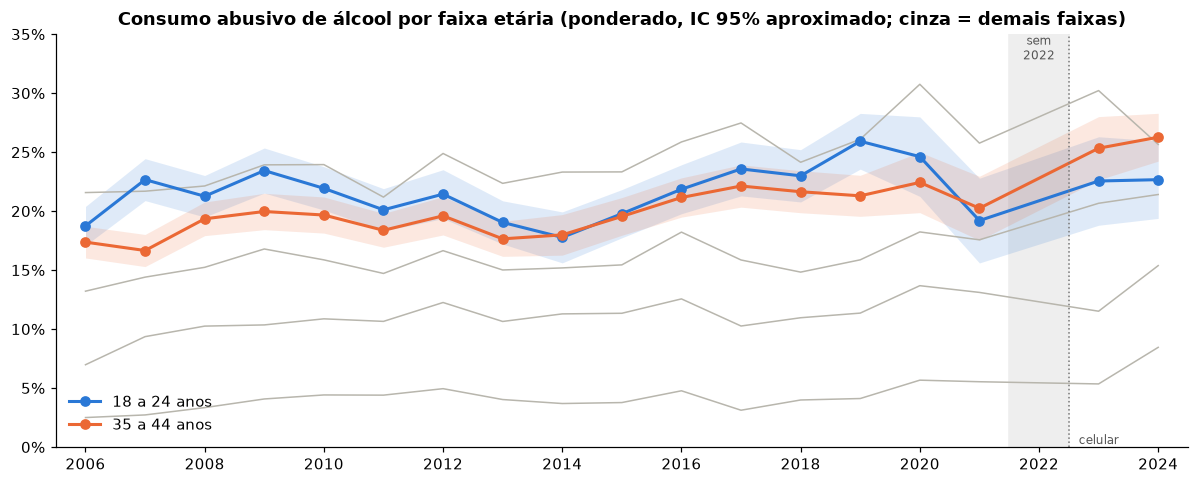

Variação 2010 -> 2024 (p.p.): {'18 a 24': 0.8, '35 a 44': 6.6}


In [24]:
por_faixa = prevalencia(explo, ['ano', 'fet'])
por_faixa['faixa'] = por_faixa['fet'].map(ROTULOS['fet'])
tabela_p1 = por_faixa.pivot(index='ano', columns='faixa', values='prev').round(1)
display(tabela_p1)

fig, ax = plt.subplots(figsize=(11, 4.5))
for f in ['2', '4', '5', '6']:
    r = por_faixa[por_faixa['fet'] == f]
    ax.plot(r['ano'], r['prev'], color=COR_OUTROS, lw=1)
linha(ax, por_faixa[por_faixa['fet'] == '1'], COR_JOVEM, '18 a 24 anos')
linha(ax, por_faixa[por_faixa['fet'] == '3'], COR_REF, '35 a 44 anos')
ax.set_ylim(0, 35)
marcar_rupturas(ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title('Consumo abusivo de álcool por faixa etária (ponderado, IC 95% aproximado; cinza = demais faixas)')
ax.legend(frameon=False, loc='lower left')
plt.tight_layout()
plt.show()

v = tabela_p1.loc[[2010, 2024], ['18 a 24', '35 a 44']]
print('Variação 2010 -> 2024 (p.p.):', (v.loc[2024] - v.loc[2010]).round(1).to_dict())

**Leitura (prévia):** entre os jovens, a prevalência ponderada foi de 21,9% em 2010 e 22,7% em 2024, **sem queda visível**, com oscilações dentro do intervalo ao longo da série. Já a faixa de 35 a 44 anos subiu cerca de 6,6 p.p. A premissa do README (jovens bebendo menos) não aparece nesta prévia para o consumo abusivo nas capitais. Isso ainda não é o teste: as rupturas de D1 a D4 (seção 14) podem mudar o retrato e precisam ser decididas antes.

### 13.2 P2: jovens por escolaridade

fesc,0 a 8 anos,9 a 11 anos,12 anos e mais
ano,,,
2006,22.5,17.4,18.7
2007,28.8,20.7,22.9
2008,22.8,19.5,24.0
2009,27.1,20.4,27.6
2010,22.5,18.5,27.7
2011,24.4,18.0,22.1
2012,25.3,17.8,26.3
2013,20.0,17.9,20.7
2014,21.1,15.9,20.0


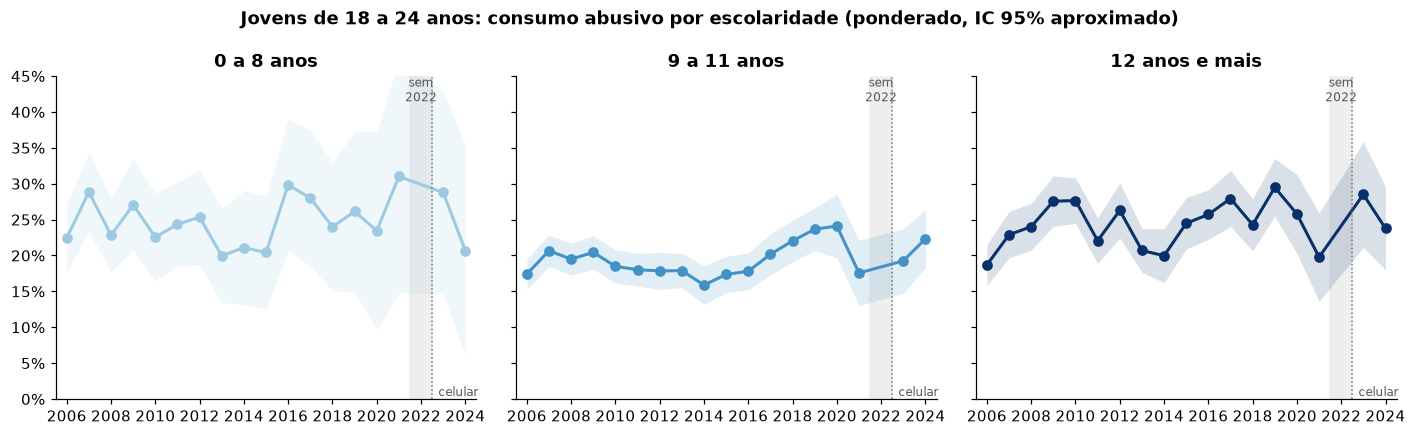

In [25]:
p2 = prevalencia(explo[jovem], ['ano', 'fesc'])
display(p2.pivot(index='ano', columns='fesc', values='prev')[list(CORES_ESC)].round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, faixa in zip(axes, CORES_ESC):
    linha(ax, p2[p2['fesc'] == faixa], CORES_ESC[faixa], faixa)
    ax.set_ylim(0, 45)
    marcar_rupturas(ax)
    ax.set_title(faixa)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.suptitle('Jovens de 18 a 24 anos: consumo abusivo por escolaridade (ponderado, IC 95% aproximado)',
             fontweight='bold')
plt.tight_layout()
plt.show()

### 13.3 P4: jovens por sexo

sexo,feminino,masculino
ano,,
2006,9.8,27.7
2007,13.8,31.8
2008,14.4,27.8
2009,14.3,31.8
2010,14.8,28.9
2011,12.2,27.8
2012,13.6,29.1
2013,14.4,23.6
2014,12.0,23.5


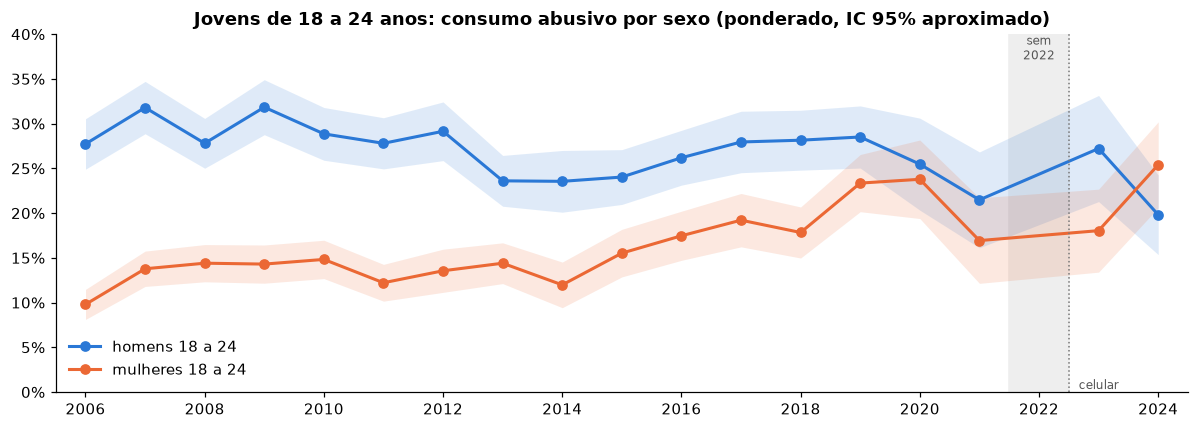

In [26]:
p4 = prevalencia(explo[jovem], ['ano', 'sexo'])
display(p4.pivot(index='ano', columns='sexo', values='prev').round(1))

fig, ax = plt.subplots(figsize=(11, 4))
linha(ax, p4[p4['sexo'] == 'masculino'], COR_JOVEM, 'homens 18 a 24')
linha(ax, p4[p4['sexo'] == 'feminino'], COR_REF, 'mulheres 18 a 24')
ax.set_ylim(0, 40)
marcar_rupturas(ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title('Jovens de 18 a 24 anos: consumo abusivo por sexo (ponderado, IC 95% aproximado)')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Leitura (prévia):** por escolaridade, as três faixas oscilam muito de um ano para outro (a faixa de 0 a 8 anos tem pouco mais de 100 jovens nas edições recentes), sem uma tendência comum clara. Por sexo aparece o movimento mais forte da prévia: entre as jovens a prevalência sobe de cerca de 15% (2010) para 25% (2024), e entre os jovens homens cai de cerca de 29% para 20%. Ou seja, a média estável dos jovens pode esconder movimentos opostos entre homens e mulheres, o que interessa diretamente à P4.

### 13.4 P5: precisão por capital

Antes de ordenar capitais, é preciso ver se a amostra permite. O gráfico mostra a largura do intervalo de 95% da prevalência dos jovens em cada capital, em 2010 e em 2024.

n                                                 largura_ic                                         
     count   mean   std    min    25%    50%    75%    max      count  mean  std   min   25%   50%   75%   max
ano                                                                                                           
2010  27.0  272.7  59.8  179.0  228.5  270.0  309.5  391.0       27.0  11.2  1.5   8.2  10.2  11.3  12.2  13.6
2024  27.0   85.0  20.9   53.0   68.5   84.0   98.5  133.0       27.0  18.9  3.1  14.6  16.5  18.0  21.2  24.8

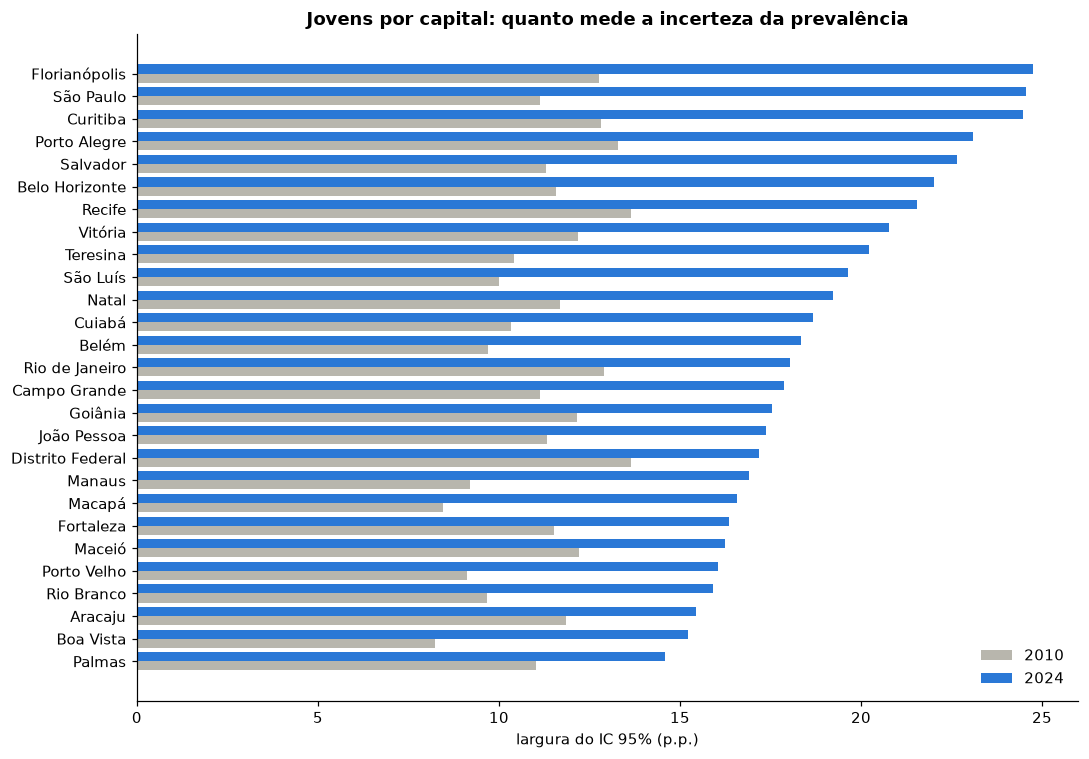

In [27]:
p5 = prevalencia(explo[jovem & explo['ano'].isin([2010, 2024])], ['ano', 'cidade'])
p5['largura_ic'] = p5['ic95_sup'] - p5['ic95_inf']
largura = p5.pivot(index='cidade', columns='ano', values='largura_ic').sort_values(2024)
display(p5.groupby('ano')[['n', 'largura_ic']].describe().round(1))

fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(largura))
ax.barh(y - 0.2, largura[2010], height=0.4, color=COR_OUTROS, label='2010')
ax.barh(y + 0.2, largura[2024], height=0.4, color=COR_JOVEM, label='2024')
ax.set_yticks(y, largura.index)
ax.set_xlabel('largura do IC 95% (p.p.)')
ax.set_title('Jovens por capital: quanto mede a incerteza da prevalência')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Leitura:** em 2010 a mediana da largura do intervalo por capital era de cerca de 11 p.p.; em 2024 é de cerca de 18 p.p., com cerca de 85 jovens por capital. Diferenças de alguns pontos entre capitais em 2024 ficam dentro do ruído amostral. Um ranking simples de capitais (P5) seria enganoso sem intervalos ou sem juntar anos.

## 14. Decisões de tratamento em aberto

Nada abaixo foi decidido. Cada linha registra um problema encontrado na exploração e as opções possíveis, para o autor decidir à luz das hipóteses, como foi feito no MVP de terras raras (seção 12 do AED v16).

| # | Problema encontrado | Seção | Opções |
|---|---|---|---|
| D1 | Não existe edição de 2022 | 7 | Ignorar o ano (série com lacuna); interpolar só em gráfico; nunca imputar dado |
| D2 | Ano final: 2024 tem mais de 90% das entrevistas por celular; 2010, só fixo | 8 | Usar 2024 e declarar a limitação; usar 2019 (último ano só fixo) como comparação de sensibilidade; comparar 2010 com 2023-2024 juntos |
| D3 | Amostra de jovens de 2024 é cerca de 1/3 da de 2010 | 7, 13 | Comparar anos isolados; juntar triênios (2009-2011 contra 2021-2024) para ganhar precisão |
| D4 | Pesos com escalas diferentes antes e depois de 2010 | 12 | Calcular sempre dentro do ano; se juntar anos, normalizar o peso para somar 1 em cada ano |
| D5 | Nomes de `q37`/`q38` contradizem o documento de orientações | 11.3 | Usar `alcabu` oficial (reproduzido em 100%); checar a redação nos questionários de 2009 e 2010 |
| D6 | `q35` muda de codificação e falta em 2024 | 11.1 | Não usar `q35` como indicador; usar só `alcabu` |
| D7 | Composição dos jovens por escolaridade mudou | 10.2 | Responder P2 dentro de cada faixa; opcionalmente padronizar a composição de 2024 pela de 2010 |
| D8 | `fesc` é imputada pelo Ministério quando `q8a` é 777/888 | 10.1 | Aceitar a imputação oficial (é a mesma usada no peso); ou excluir os imputados e medir o efeito |
| D9 | Capitais com poucos jovens e intervalos largos | 7.1, 13.4 | Ranking de capitais com IC; agrupar por região; juntar anos; só destacar diferenças fora do IC |
| D10 | `chave` vazia ou repetida em parte da série | 6 | Criar chave substituta (ano + número da linha) na camada bronze |
| D11 | 2020 e 2021 coletados na pandemia, com amostra reduzida | 7, 13 | Manter na série com nota; excluir de médias de período |
| D12 | Campos de texto livre com codificação mista; `regiao` vazia em 2012 | 2.1, 4.1 | Texto livre fora do recorte (não responde às perguntas e pode conter informação pessoal); derivar a região de `cidade` |

## 15. Integridade e saídas

In [28]:
assert pd.util.hash_pandas_object(bruto, index=True).sum() == DIGITAL_BRUTO, 'O bruto foi alterado!'
print('Bruto intacto: a impressão digital é a mesma da leitura.')

os.makedirs(PASTA_SAIDAS, exist_ok=True)
saidas = {
    'amostra_por_ano.csv': amostra,
    'vazios_por_ano.csv': mapa_vazios.round(2),
    'pesos_por_ano.csv': pesos,
    'previa_prevalencia_faixa_etaria.csv': por_faixa,
    'previa_prevalencia_jovens_escolaridade.csv': p2,
    'previa_prevalencia_jovens_sexo.csv': p4,
    'previa_prevalencia_jovens_capital.csv': p5,
}
for nome, tabela in saidas.items():
    tabela.to_csv(os.path.join(PASTA_SAIDAS, nome), encoding='utf-8-sig')
print(f'{len(saidas)} tabelas salvas em {PASTA_SAIDAS}')

Bruto intacto: a impressão digital é a mesma da leitura.
7 tabelas salvas em saidas_aed_v1


## 16. Síntese e próximos passos

1. **A base certa existe e está aberta**: Vigitel 2006-2024 harmonizado, um arquivo, peso único (`pesorake2025`) e o indicador `alcabu` pronto e reproduzível.
2. **Três rupturas** pesam sobre a comparação de 2010 com 2024: falta 2022, a coleta passou de telefone fixo para celular em 2023-2024 e a amostra de jovens encolheu para cerca de um terço.
3. **Pulos de questionário** explicam quase todos os vazios: eles não são dados perdidos e não devem ser imputados.
4. **A prévia (seção 13) não mostra queda entre os jovens** de 2010 para 2024 (21,9% e 22,7%), mas mostra movimentos opostos por sexo e alta entre os de 35 a 44 anos. Se o teste formal confirmar, a hipótese do README será refutada no critério (a), e isso é um resultado válido do MVP: o enunciado do trabalho trata a hipótese refutada como aprendizado. Também pode ser o caso de reformular a pergunta de negócio (por exemplo, para o recorte por sexo) antes de seguir, mantendo a formulação original documentada.

**Próximo passo:** o autor decide D1 a D12; depois vêm a camada tratada (silver) com as decisões aplicadas e o teste formal das hipóteses na camada analítica do Databricks.